# 1. deo - Osnovna klasifikacija

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np

In [2]:
from pathlib import Path

data_path = Path("Data/churn.csv")
if data_path.is_file():
    df = pd.read_csv(data_path)
else:
    # U Colab okruženju koristimo isti skup podataka iz repozitorijuma.
    df = pd.read_csv(
        "https://raw.githubusercontent.com/stefisha/MLWorkshop-BEST/main/Data/churn.csv"
    )
df.head()

,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churn
0,OH,107,area_code_415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,no
1,NJ,137,area_code_415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,no
2,OH,84,area_code_408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,no
3,OK,75,area_code_415,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,no
4,MA,121,area_code_510,no,yes,24,218.2,88,37.09,348.5,108,29.62,212.6,118,9.57,7.5,7,2.03,3,no


In [3]:
X = df.drop('churn', axis=1)
y = df['churn']

#X = df.iloc[:, :-1] #Uzimamo sve kolone osim poslednje
#y = df.iloc[:, -1] #Uzimamo poslednju kolonu

In [4]:
X.head()

,state,account_length,area_code,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls
0,OH,107,area_code_415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1
1,NJ,137,area_code_415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0
2,OH,84,area_code_408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2
3,OK,75,area_code_415,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3
4,MA,121,area_code_510,no,yes,24,218.2,88,37.09,348.5,108,29.62,212.6,118,9.57,7.5,7,2.03,3


In [5]:
X.dtypes

state                             object
account_length                     int64
area_code                         object
international_plan                object
voice_mail_plan                   object
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
dtype: object

In [6]:
X["area_code"]       

0       area_code_415
1       area_code_415
2       area_code_408
3       area_code_415
4       area_code_510
            ...      
4245    area_code_415
4246    area_code_408
4247    area_code_408
4248    area_code_408
4249    area_code_415
Name: area_code, Length: 4250, dtype: object

In [7]:
X = df.select_dtypes(include=['int64', 'float64'])

In [8]:
#X.drop(['area_code'], axis = 1)

In [9]:
y.head()

0    no
1    no
2    no
3    no
4    no
Name: churn, dtype: object

In [10]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=3)

In [11]:
model.fit(X, y)

DecisionTreeClassifier(max_depth=3)

In [12]:
model.predict(X)

array(['no', 'no', 'no', ..., 'no', 'no', 'no'], dtype=object)

In [13]:
pd.DataFrame({'stvarno':y,'predvidjeno':model.predict(X)}).head(15)

,stvarno,predvidjeno
0,no,no
1,no,no
2,no,no
3,no,no
4,no,no
5,no,no
6,no,no
7,no,no
8,yes,yes
9,no,no


In [14]:
from sklearn.metrics import accuracy_score
predictions = model.predict(X)
accuracy_score(y, predictions)
f'Naš model je {round(accuracy_score(y, model.predict(X)) * 100, 2)}% tačan'

'Naš model je 91.22% tačan'

### Drugi algoritmi

In [15]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(X, y)
accuracy_score(y, model.predict(X))

0.8870588235294118

In [16]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier()
model.fit(X, y)
accuracy_score(y, model.predict(X))

0.908

In [17]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X, y)
accuracy_score(y, model.predict(X))

0.8616470588235294

### Kompleksniji model (Decision boundaries)

In [18]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=5)
model.fit(X, y)
accuracy_score(y, model.predict(X))

0.9336470588235294

# 2. Deo - Evaluation

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2021)

In [20]:
model = LogisticRegression().fit(X_train, y_train)
accuracy_score(y_test, model.predict(X_test))

0.8596078431372549

In [21]:
model = GaussianNB().fit(X_train, y_train)
accuracy_score(y_test, model.predict(X_test))

0.883921568627451

In [22]:
model = KNeighborsClassifier().fit(X_train, y_train)
accuracy_score(y_test, model.predict(X_test))

0.8776470588235294

In [23]:
model = DecisionTreeClassifier(max_depth=20).fit(X_train, y_train)
accuracy_score(y_test, model.predict(X_test))

0.8580392156862745

In [24]:
model = DecisionTreeClassifier(max_depth=5).fit(X_train, y_train)
accuracy_score(y_test, model.predict(X_test))

0.9137254901960784

ponavljan vise puta... varijabilnost rezultata!

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
model = DecisionTreeClassifier(max_depth=20).fit(X_train, y_train)
accuracy_score(y_test, model.predict(X_test))

0.8619607843137255

### Cross-validation

In [26]:
from sklearn.model_selection import cross_val_score
model = DecisionTreeClassifier(max_depth=20)
results = cross_val_score(model, X, y, cv=10, scoring='accuracy')
print(results)

[0.87058824 0.85647059 0.88235294 0.88470588 0.87764706 0.88
 0.88470588 0.85647059 0.86823529 0.87764706]


In [27]:
print(results.mean(),results.std())

0.8738823529411764 0.010103957907568906


### Kriva učenja

Matplotlib is building the font cache; this may take a moment.


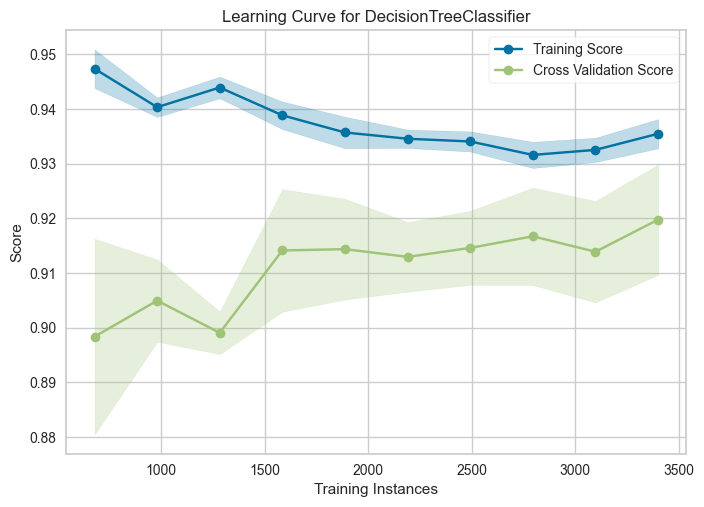

In [28]:
#!pip install yellowbrick
from yellowbrick.model_selection import LearningCurve
model = DecisionTreeClassifier(max_depth=5)
steps = np.linspace(0.2, 1.0, 10)
visualizer = LearningCurve(model, cv=5, scoring='accuracy', train_sizes=steps, n_jobs=4)
visualizer.fit(X, y)        # Fit the data to the visualizer
visualizer.show();

# 3. Deo - Metrike evaluacije

## Baseline model

In [29]:
y.value_counts()

churn
no     3652
yes     598
Name: count, dtype: int64

In [30]:
predictions = np.repeat(0, len(y))

In [31]:
# Eksplicitno mapiranje: bool("no") je takođe True.
y = y.map({"no": False, "yes": True})
if y.isna().any():
    raise ValueError("Očekivane oznake ciljne promenljive su yes i no.")
y = y.astype(bool)

In [32]:
y.dtype

dtype('bool')

In [33]:
predictions.dtype

dtype('int64')

In [34]:
accuracy_score(y, predictions)

0.8592941176470589

### Metrike

In [35]:
from sklearn.metrics import confusion_matrix
model = DecisionTreeClassifier(max_depth=5)
model = model.fit(X,y)
confusion_matrix(y_true=y, y_pred=model.predict(X))

array([[3611,   41],
       [ 241,  357]])

In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score
y_hat = model.predict(X)
prec = precision_score(y, y_hat)
rec = recall_score(y, y_hat)
f1 = f1_score(y, y_hat)
f'Mere performansi modela su {np.round(prec * 100, 2)}% preciznosti, {np.round(rec * 100, 2)}% odziva i {np.round(f1 * 100, 2)}% F mere'

'Mere performansi modela su 89.7% preciznosti, 59.7% odziva i 71.69% F mere'

In [37]:
cross_val_score(model, X, y, cv=10, scoring='precision').mean()

0.8292550889394393

### Diskusija: Da li je ovaj model dobar?

### Cene gresaka

In [38]:
confusion_matrix(y, model.predict(X))

array([[3611,   41],
       [ 241,  357]])

In [39]:
costs = np.array([[0, 5], [1, 0]])
costs

array([[0, 5],
       [1, 0]])

In [40]:
confusion_matrix(y, model.predict(X)) * costs

array([[  0, 205],
       [241,   0]])

In [41]:
(confusion_matrix(y, model.predict(X)) * costs).sum().sum()

446

In [42]:
def matrica_troskova(y_true, y_pred, costs):
    conf_max = confusion_matrix(y_true, y_pred)
    return (conf_max * costs).sum()/conf_max.sum()

In [43]:
matrica_troskova(y,model.predict(X), costs)

0.10494117647058823

In [44]:
from sklearn.metrics import make_scorer
costs_scorer = make_scorer(matrica_troskova, costs=costs, greater_is_better=False)

In [45]:
#cross_val_score(LogisticRegression(), X, y, cv=10, scoring=costs_scorer)

# Deo 4. - Granice odluke i AUC

In [46]:
#model = LogisticRegression().fit(X, y)
#robas = model.predict_proba(X)
#probas

In [47]:
#res = pd.DataFrame({'stvarno': y, 'predvidjeno': probas[:, 1]})
#res.head()

In [48]:
#confusion_matrix(y, model.predict(X))

In [49]:
#model.predict_proba(X)[:, 1]

In [50]:
#predictions = model.predict_proba(X)[:, 1] >= 0.2
#confusion_matrix(y, predictions)

In [51]:
#import matplotlib.pyplot as plt
#from sklearn.metrics import roc_curve
#model = LogisticRegression()
#model.fit(X, y)
#fpr, tpr, thresholds = roc_curve(y, model.predict_proba(X)[:, 1])
#plt.plot(fpr, tpr)

In [52]:
#from sklearn.metrics import roc_auc_score
#roc_auc_score(y, model.predict_proba(X)[:, 1])

In [53]:
#model = LogisticRegression()
#results = cross_val_score(model, X, y, cv=10, scoring='roc_auc')
#print(results.mean())
#print(results.std())